### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DPNM_Y = data.copy()
mask = (DPNM_Y['category']=='pulses and nuts') & (DPNM_Y['region']=='Yangon')
DPNM_Y = DPNM_Y.loc[mask]
DPNM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4082,1/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1820.00,1.0225
4337,2/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1820.00,1.0225
4613,3/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1750.00,0.9831
4880,4/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1732.98,0.9736
5141,5/15/2011,Yangon,Yangon (West),Yangon,pulses and nuts,Chickpeas,Chickpeas,NaN,1.6 KG,actual,Retail,MMK,1653.61,0.9290


In [12]:
obv_st_date = pd.to_datetime("2011-01-01")

In [13]:
DPNM_Y = DPNM_Y[['date', 'price']]
DPNM_Y['date'] = pd.to_datetime(DPNM_Y['date'])
mask = (DPNM_Y['date']>=obv_st_date) & (DPNM_Y['date']<=obv_end_date)
DPNM_Y = DPNM_Y.loc[mask]
DPNM_Y = DPNM_Y.set_index('date')
DPNM_Y.head()

,price
date,
2011-01-15,1820.00
2011-02-15,1820.00
2011-03-15,1750.00
2011-04-15,1732.98
2011-05-15,1653.61


In [14]:
DPNM_Y = DPNM_Y.resample('MS').mean()
DPNM_Y.head()

,price
date,
2011-01-01,1820.00
2011-02-01,1820.00
2011-03-01,1750.00
2011-04-01,1732.98
2011-05-01,1653.61


In [15]:
DPNM_Y.shape

(133, 1)

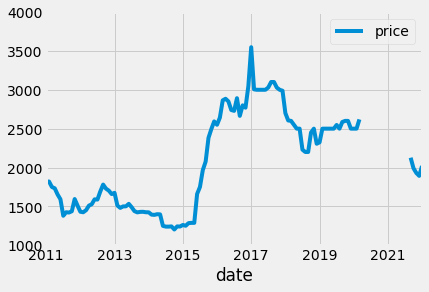

In [16]:
DPNM_Y.plot(grid=True)
plt.show()

It has some missing data.

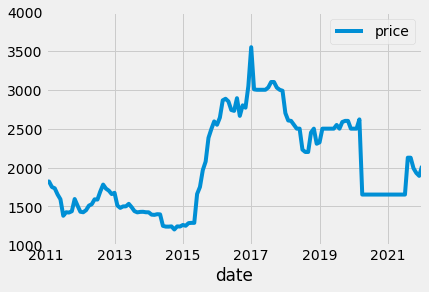

In [17]:
DPNM_Y = DPNM_Y.bfill()
DPNM_Y.plot(grid=True)
plt.show()

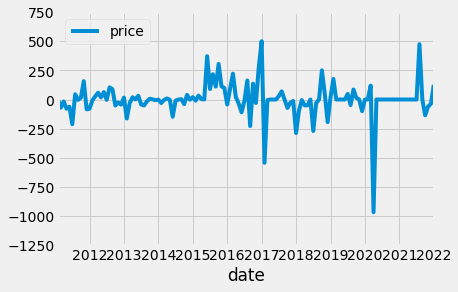

In [18]:
DPNM_Y_diff1 = DPNM_Y.diff(1).dropna()
DPNM_Y_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [19]:
RW_DPNM_Y= adfuller(DPNM_Y_diff1)
RW_DPNM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

2.031835175006987e-21

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

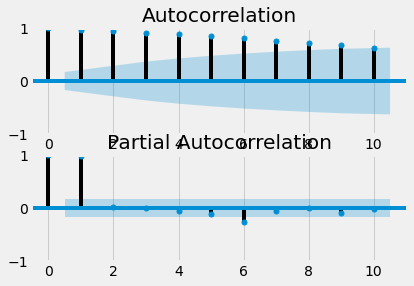

In [20]:
fig, axes=plt.subplots(2,1)
plot_acf(DPNM_Y, lags=10, ax=axes[0])
plot_pacf(DPNM_Y, lags=10, ax=axes[1])
plt.show()

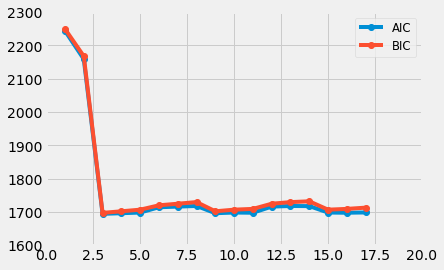

In [21]:
AIC, BIC = AIC_BIC_withOrderRange(DPNM_Y, p=3, d=2, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 
# 6:(1,0,0), 7:(1,0,1), 8:(1,0,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 
# 12:(2,0,0), 13:(2,0,1), 14:(2,0,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [22]:
AIC, BIC

(array([2415.27163407, 2243.37184172, 2158.74317405, 1694.38785025,
        1696.2804566 , 1698.25403808, 1714.19215735, 1716.0920552 ,
        1718.07141619, 1696.28777564, 1698.27294392, 1697.71666626,
        1716.09498767, 1717.99816589, 1717.55622992, 1698.25544972,
        1697.70522641, 1698.56801377]),
 array([2418.1619832 , 2249.15253997, 2167.41422143, 1697.27065217,
        1702.04606044, 1706.90244385, 1719.97285561, 1724.76310258,
        1729.6328127 , 1702.05337949, 1706.92134969, 1709.24787395,
        1724.76603505, 1729.5595624 , 1732.00797556, 1706.90385548,
        1709.2364341 , 1712.98202339]))

We will run again 3:(0,1,0), 4:(0,1,1), 5:(0,1,2), 9:(1,1,0), 10:(1,1,1), 11:(1,1,2), 15:(2,1,0), 16:(2,1,1), 17:(2,1,2)

In [23]:
mod_orders = [
    (0,1,0), 
    (0,1,1), 
    (0,1,2), 
    (1,1,0), 
    (1,1,1), 
    (1,1,2), 
    (2,1,0), 
    (2,1,1), 
    (2,1,2)
]

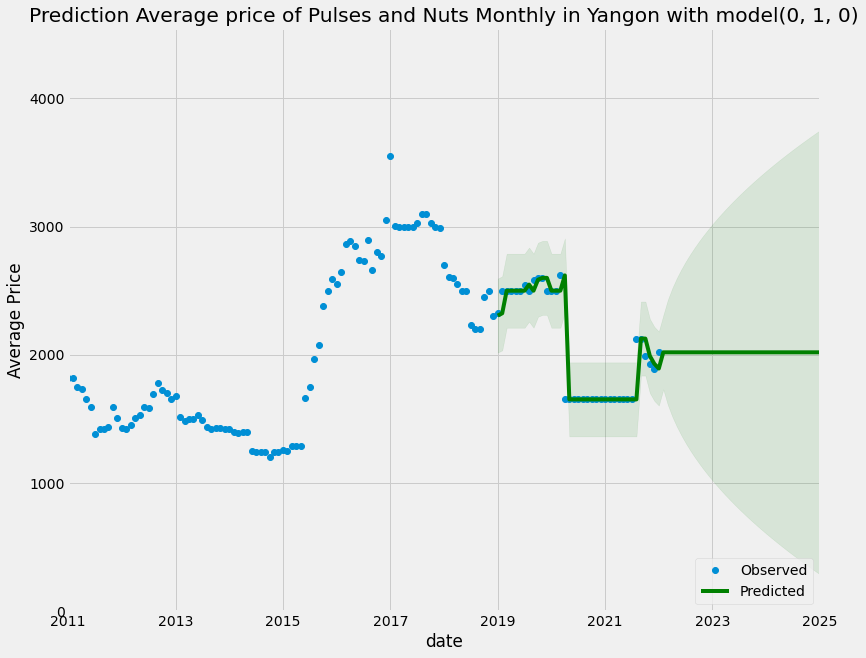

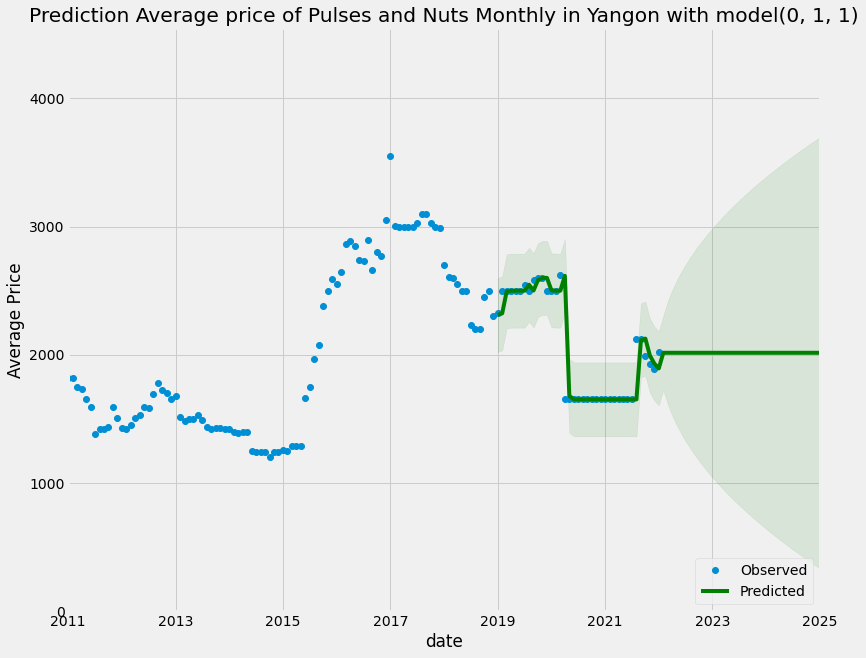

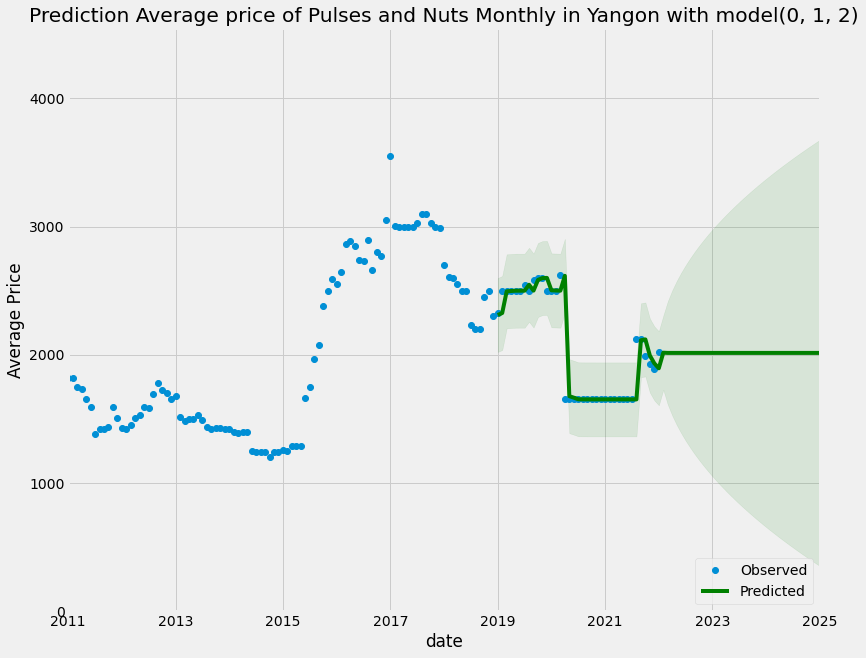

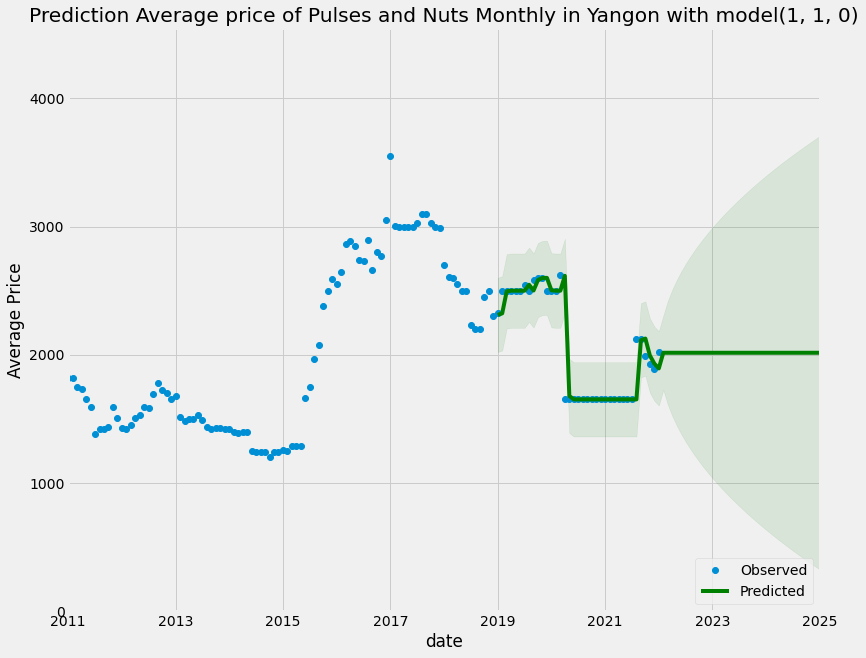

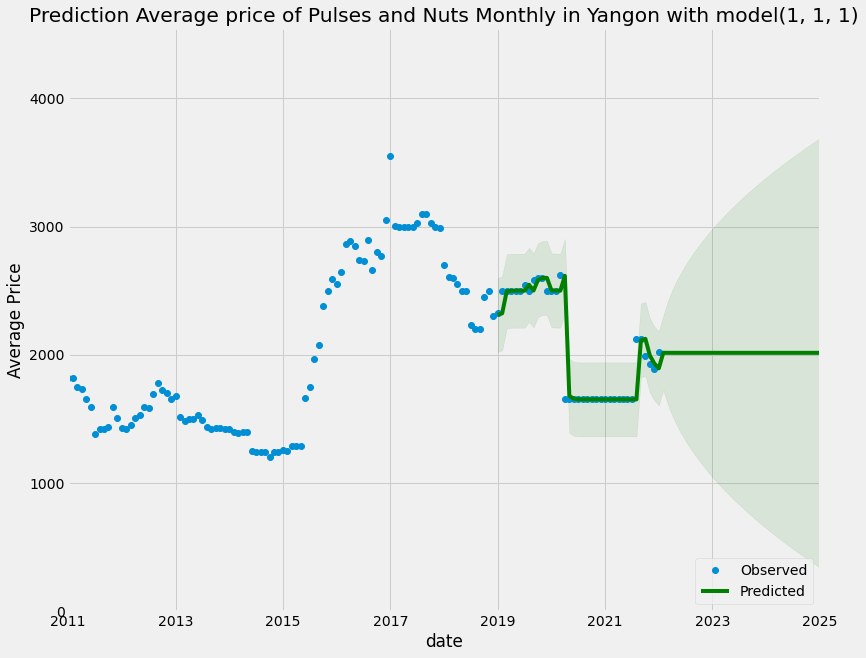

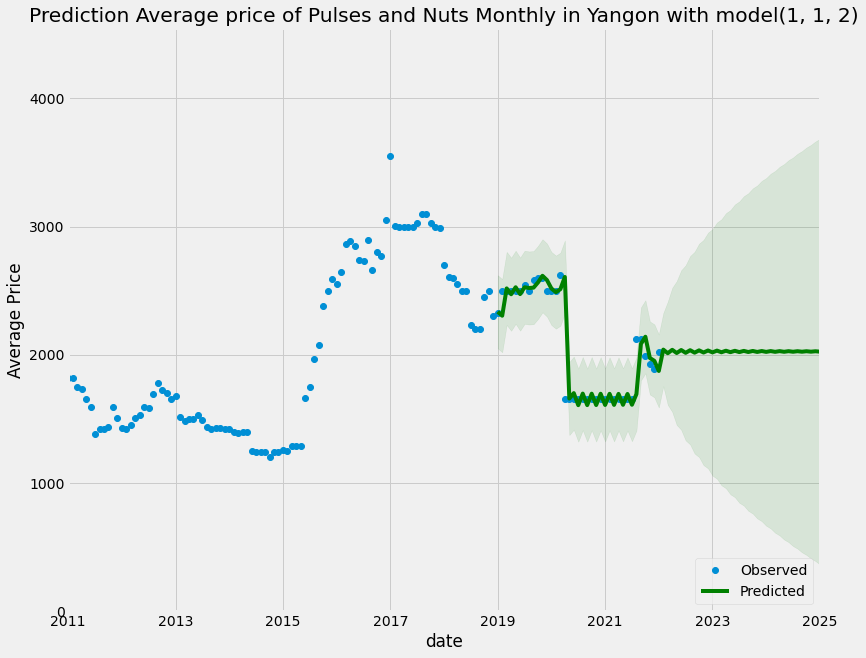

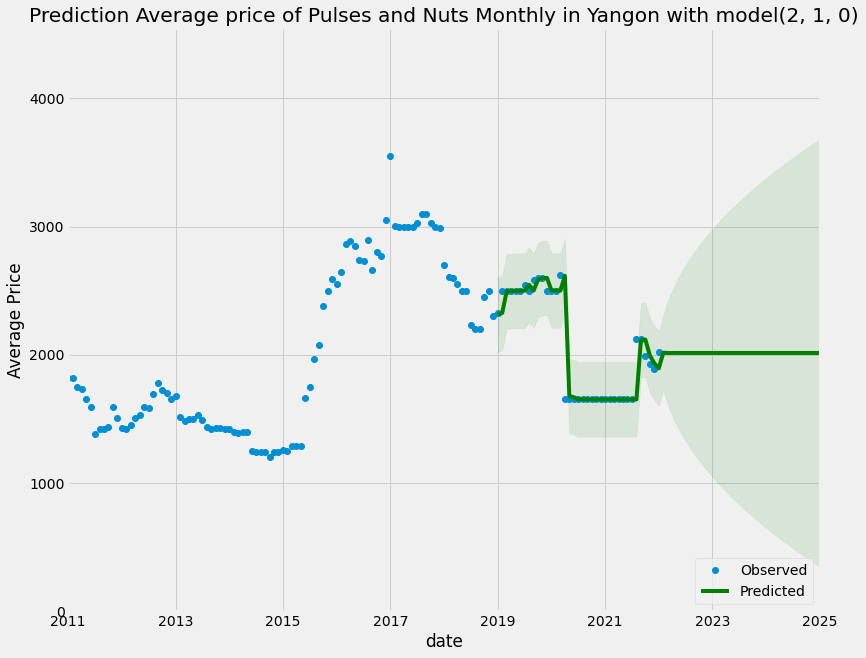

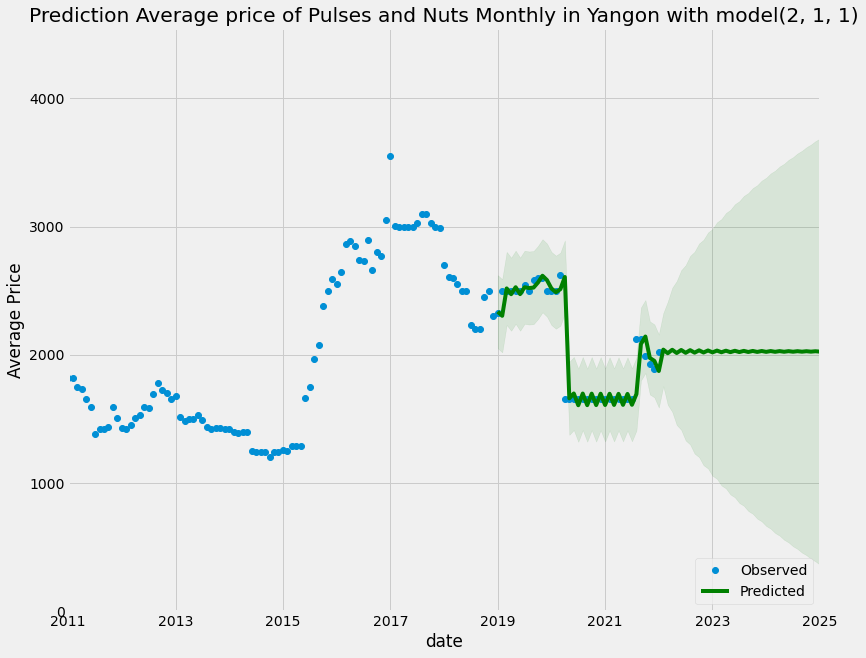

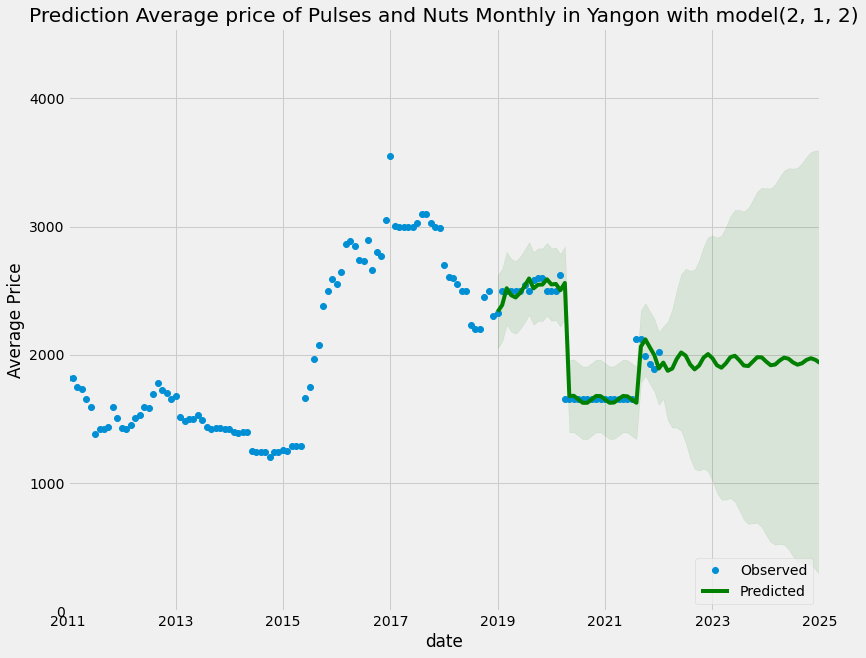

In [24]:
DPNM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DPNM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Pulses and Nuts Monthly in Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DPNM_Y_models.append(model)

Now we choose (0,1,0)

In [25]:
DPNM_Y_model = DPNM_Y_models[0]

In [26]:
DPNM_Y_pred = DPNM_Y_model.predict(pred_st_date, pred_end_date)
DPNM_Y_pred

2019-01-01    2305.88
2019-02-01    2323.81
2019-03-01    2500.00
2019-04-01    2500.00
2019-05-01    2500.00
               ...   
2024-09-01    2019.40
2024-10-01    2019.40
2024-11-01    2019.40
2024-12-01    2019.40
2025-01-01    2019.40
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64